# Intro
**Short background**. Unlike crystals, which can be always be defined geomtrically by a lattice, **amorphous** materials are harder to construct, even if all you need is a small ~100-atom model. Atomic models for amorphous materials require computationally demanding and time-consuming procedures to obtain: typically you create the material in question in its liquid state first, followed by gradual cooling (also known as quenching). The slower you cool it, the more realistic the outcomes are, but you also have to spend more time simulating the cooling process.

**Recent breakthrough**. Recently it has become possible to *generate* amorphous structures using diffusion models that  denoise randomly sampled atomic coordinates to create physically meaningful amorphous structures. Their github repo is
https://github.com/digital-synthesis-lab/DM2

**Our task**. For this project, we'll extend this recent diffusion model to generate targeted **defects** for amorphous materials.

**This notebook.** This notebook contains a few minimal code snippets that demonstrates the goal of our UNT AI summer project at a proof-of-concept level.  Because it's meant to be a minimal demo, the code below includes many major simplifications. In the full project we will flesh these out based on the DM2 code, using Graph Neural Networks (GNN).

In the  minimal demo:
(1) GNNs have been replaced by a simple MLP here for simplicity.
(2) Atomic structures that represent amorphous structures are small. Realistically they'll be at least a few hundred atoms.
(3) Atomic structures for amorphous structures used for training are not taken from actual quantum mechanically calculations. They're generated at random here for simplicity.

Gemini was used to generate the code, with some human fine tuning.


# 1. Baseline: train on amorphous structures, generate amorphous structures

Training on 3x3 amorphous lattice...
Epoch 0000 | Loss: 1.00500
Epoch 0300 | Loss: 0.12512
Epoch 0600 | Loss: 0.14092
Epoch 0900 | Loss: 0.19950
Epoch 1200 | Loss: 0.05888


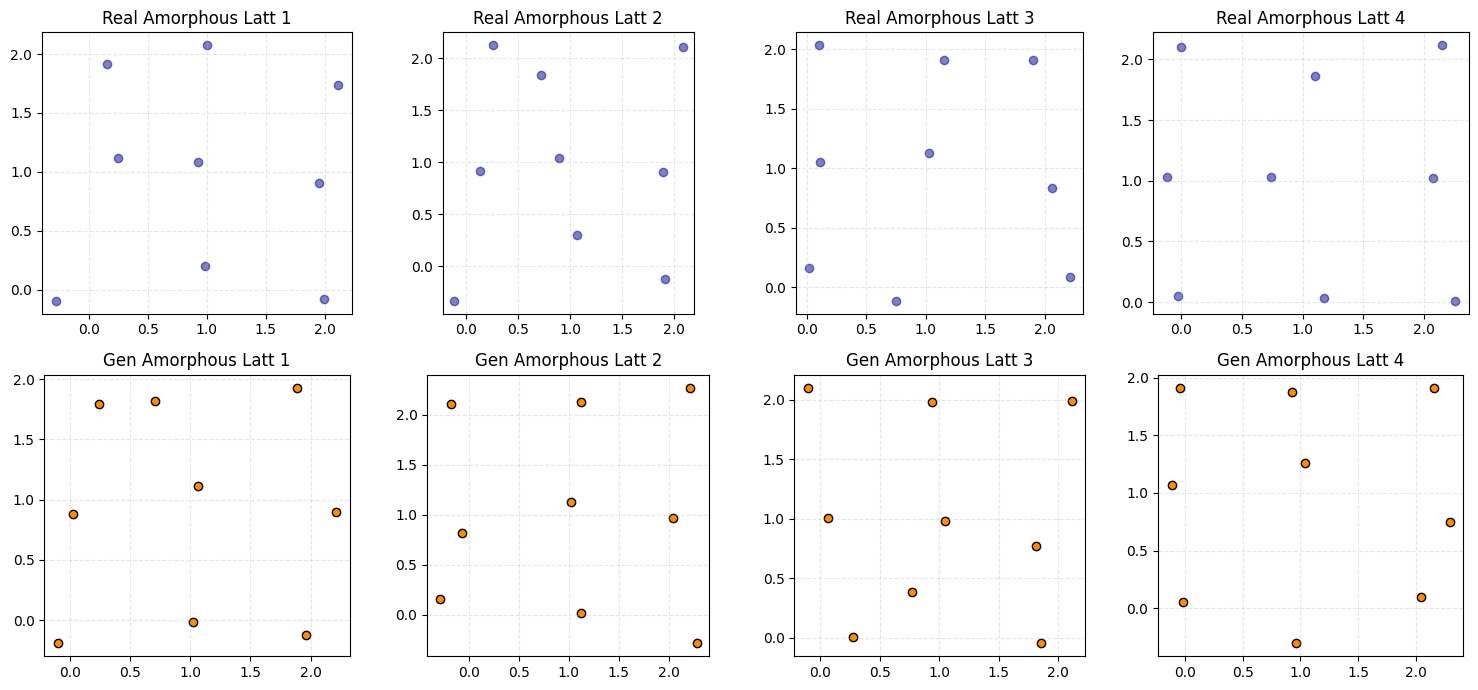

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# --- 1. PERIODIC LATTICE DATA GENERATION ---
def get_lattice_data(n_samples=2000, grid_size=3):
    """Generates a jittered 2D grid of atoms."""
    # Create an ideal grid (e.g., 0 to 2 for a 3x3)
    x = np.linspace(0, grid_size-1, grid_size)
    y = np.linspace(0, grid_size-1, grid_size)
    xv, yv = np.meshgrid(x, y)
    ideal_lattice = np.stack([xv.flatten(), yv.flatten()], axis=1)

    n_atoms = grid_size**2
    data = []
    for _ in range(n_samples):
        # Apply "amorphous" disorder (jitter)
        # We use a standard deviation to represent the 'fictive temperature' of the disorder
        jitter = np.random.normal(0, 0.15, ideal_lattice.shape)
        sample = ideal_lattice + jitter
        data.append(sample.flatten())

    return torch.tensor(np.array(data), dtype=torch.float32), n_atoms

# --- 2. THE SCORE-BASED MODEL ---
class LatticeScoreNet(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim + 1, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256, input_dim)
        )

    def forward(self, x, t):
        t_stack = torch.ones((x.shape[0], 1), device=x.device) * t
        xt = torch.cat([x, t_stack], dim=1)
        return self.net(xt)

# --- 3. DIFFUSION HYPERPARAMETERS ---
grid_size = 3
data, n_atoms = get_lattice_data(n_samples=3000, grid_size=grid_size)
input_dim = n_atoms * 2
n_steps = 200
betas = torch.linspace(1e-4, 0.02, n_steps)

model = LatticeScoreNet(input_dim)
optimizer = torch.optim.Adam(model.parameters(), lr=8e-4)

# --- 4. TRAINING LOOP ---
print(f"Training on {grid_size}x{grid_size} amorphous lattice...")
for epoch in range(1201):
    optimizer.zero_grad()
    t_idx = np.random.randint(1, n_steps)

    # Forward Diffusion (Noise Injection)
    noise = torch.randn_like(data)
    alpha_bar = torch.prod(1 - betas[:t_idx])
    x_t = torch.sqrt(alpha_bar) * data + torch.sqrt(1 - alpha_bar) * noise

    # Predict Noise
    pred_noise = model(x_t, t_idx/n_steps)
    loss = nn.MSELoss()(pred_noise, noise)

    loss.backward()
    optimizer.step()

    if epoch % 300 == 0:
        print(f"Epoch {epoch:04d} | Loss: {loss.item():.5f}")

# --- 5. REVERSE SAMPLING ---
@torch.no_grad()
def generate_lattices(n_gen=4):
    gen_samples = []
    for _ in range(n_gen):
        x = torch.randn((1, input_dim))
        for t in reversed(range(1, n_steps)):
            z = torch.randn_like(x) if t > 1 else 0
            alpha = 1 - betas[t]
            alpha_bar = torch.prod(1 - betas[:t])

            noise_pred = model(x, t/n_steps)
            x = (1 / torch.sqrt(alpha)) * (x - ((1 - alpha) / torch.sqrt(1 - alpha_bar)) * noise_pred)
            x = x + torch.sqrt(betas[t]) * z
        gen_samples.append(x.view(n_atoms, 2).numpy())
    return gen_samples

# --- 6. VISUALIZATION ---
real_samples = data[:4].view(4, n_atoms, 2).numpy()
fake_samples = generate_lattices(4)

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for i in range(4):
    # Plot Real
    axes[0, i].scatter(real_samples[i,:,0], real_samples[i,:,1], c='darkblue', alpha=0.5)
    axes[0, i].set_title(f"Real Amorphous Latt {i+1}")
    axes[0, i].set_aspect('equal')
    axes[0, i].grid(True, linestyle='--', alpha=0.3)

    # Plot Generated
    axes[1, i].scatter(fake_samples[i][:,0], fake_samples[i][:,1], c='darkorange', edgecolors='k')
    axes[1, i].set_title(f"Gen Amorphous Latt {i+1}")
    axes[1, i].set_aspect('equal')
    axes[1, i].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

# 2. Same but with GPU (use a GPU runtime in Colab)

Using device: cuda
Training Diffusion Model...
Epoch 0000 | Loss: 1.01393
Epoch 0500 | Loss: 0.04203
Epoch 1000 | Loss: 0.01730
Epoch 1500 | Loss: 0.23039
Epoch 2000 | Loss: 0.05703


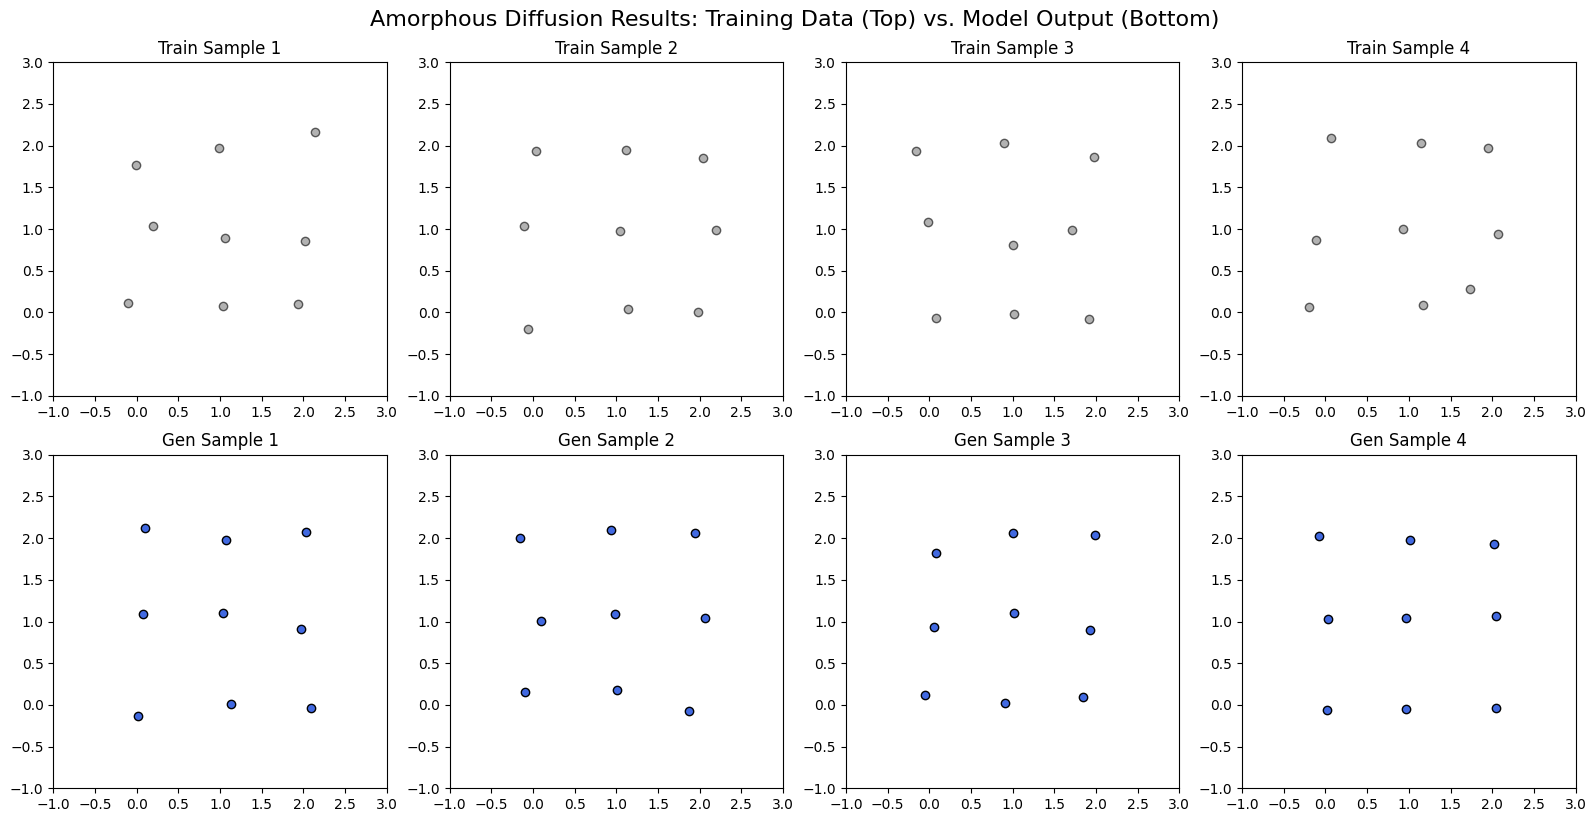

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# --- 1. GPU SETUP ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# --- 2. PERIODIC LATTICE DATA GENERATION ---
def get_lattice_data(n_samples=5000, grid_size=3):
    x = np.linspace(0, grid_size-1, grid_size)
    y = np.linspace(0, grid_size-1, grid_size)
    xv, yv = np.meshgrid(x, y)
    ideal_lattice = np.stack([xv.flatten(), yv.flatten()], axis=1)

    n_atoms = grid_size**2
    data = []
    for _ in range(n_samples):
        # Adding 'amorphous' jitter to represent the structural disorder
        jitter = np.random.normal(0, 0.12, ideal_lattice.shape)
        sample = ideal_lattice + jitter
        data.append(sample.flatten())

    return torch.tensor(np.array(data), dtype=torch.float32).to(device), n_atoms

# --- 3. SCORE-BASED MODEL (MLP) ---
class LatticeScoreNet(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim + 1, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, input_dim)
        )

    def forward(self, x, t):
        # x: (batch, input_dim), t: float scalar
        t_tensor = torch.full((x.shape[0], 1), t, device=x.device)
        xt = torch.cat([x, t_tensor], dim=1)
        return self.net(xt)

# --- 4. HYPERPARAMETERS ---
grid_size = 3
train_data, n_atoms = get_lattice_data(grid_size=grid_size)
input_dim = n_atoms * 2
n_steps = 200
betas = torch.linspace(1e-4, 0.02, n_steps).to(device)

model = LatticeScoreNet(input_dim).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)

# --- 5. TRAINING LOOP ---
print("Training Diffusion Model...")
model.train()
for epoch in range(2001):
    optimizer.zero_grad()

    # Pick a random timestep
    t_idx = np.random.randint(1, n_steps)
    alpha_bar = torch.prod(1 - betas[:t_idx])

    # Forward Diffusion: x_t = sqrt(alpha_bar) * x_0 + sqrt(1-alpha_bar) * epsilon
    noise = torch.randn_like(train_data).to(device)
    x_t = torch.sqrt(alpha_bar) * train_data + torch.sqrt(1 - alpha_bar) * noise

    # Predict the added noise
    pred_noise = model(x_t, t_idx/n_steps)
    loss = nn.MSELoss()(pred_noise, noise)

    loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch:04d} | Loss: {loss.item():.5f}")

# --- 6. SAMPLING FUNCTION ---
@torch.no_grad()
def sample_batch(n_batch=4):
    model.eval()
    # Start with pure Gaussian noise on the GPU
    x = torch.randn((n_batch, input_dim)).to(device)

    for t in reversed(range(1, n_steps)):
        z = torch.randn_like(x) if t > 1 else 0
        alpha = 1 - betas[t]
        alpha_bar = torch.prod(1 - betas[:t])

        # Predicted score points toward the high-probability amorphous manifold
        noise_pred = model(x, t/n_steps)
        x = (1 / torch.sqrt(alpha)) * (x - ((1 - alpha) / torch.sqrt(1 - alpha_bar)) * noise_pred)
        x = x + torch.sqrt(betas[t]) * z

    return x.view(n_batch, n_atoms, 2).cpu().numpy()

# --- 7. VISUALIZATION ---
# Grab some real samples from training data for comparison
real_samples = train_data[:4].view(4, n_atoms, 2).cpu().numpy()
# Generate new samples from noise
generated_samples = sample_batch(n_batch=4)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i in range(4):
    # Top Row: Real "Amorphous" training data
    axes[0, i].scatter(real_samples[i,:,0], real_samples[i,:,1], c='gray', alpha=0.6, edgecolors='k')
    axes[0, i].set_title(f"Train Sample {i+1}")
    axes[0, i].set_aspect('equal')
    axes[0, i].set_xlim(-1, 3); axes[0, i].set_ylim(-1, 3)

    # Bottom Row: AI-Generated Amorphous structures
    axes[1, i].scatter(generated_samples[i,:,0], generated_samples[i,:,1], c='royalblue', edgecolors='k')
    axes[1, i].set_title(f"Gen Sample {i+1}")
    axes[1, i].set_aspect('equal')
    axes[1, i].set_xlim(-1, 3); axes[1, i].set_ylim(-1, 3)

plt.tight_layout()
plt.suptitle("Amorphous Diffusion Results: Training Data (Top) vs. Model Output (Bottom)", y=1.02, fontsize=16)
plt.show()

# 3. Training on a defect type (a Frenkel pair), generate this defect type

Training Version 1 with Frenkel Defects...
Epoch 0000 | Loss: 0.98927
Epoch 0500 | Loss: 0.17310
Epoch 1000 | Loss: 0.02008
Epoch 1500 | Loss: 0.02272
Epoch 2000 | Loss: 0.01396
Epoch 2500 | Loss: 0.02282


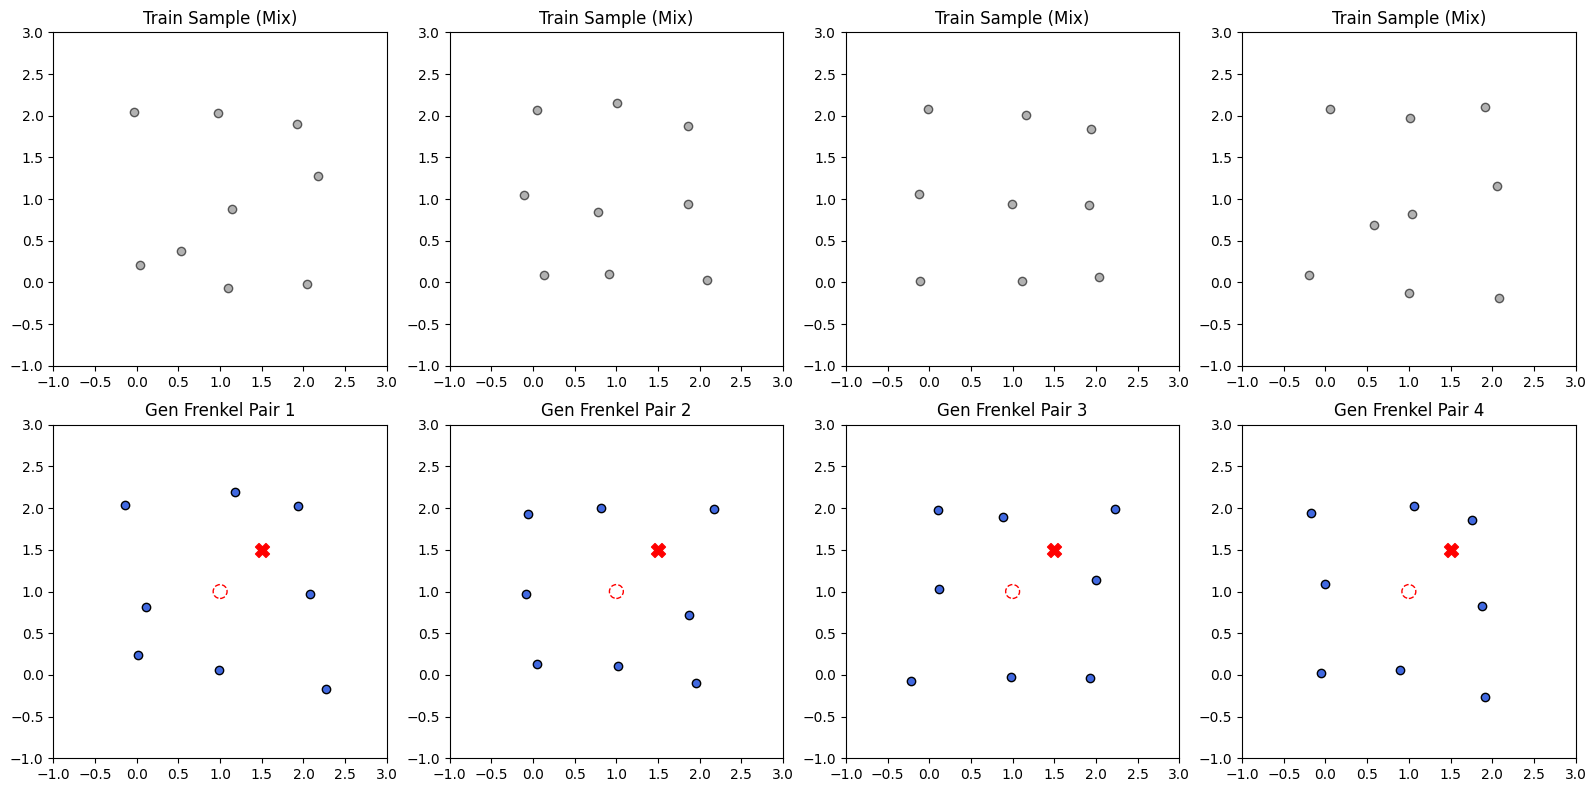

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# --- 1. GPU SETUP ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- 2. FRENKEL PAIR DATA GENERATION ---
def get_lattice_data(n_samples=6000, grid_size=3):
    x = np.linspace(0, grid_size-1, grid_size)
    y = np.linspace(0, grid_size-1, grid_size)
    xv, yv = np.meshgrid(x, y)
    ideal_lattice = np.stack([xv.flatten(), yv.flatten()], axis=1)

    n_atoms = grid_size**2
    data = []
    for _ in range(n_samples):
        pos = ideal_lattice.copy()

        # 50% chance of a Frenkel Pair
        if np.random.rand() > 0.5:
            # Pick one atom to be the interstitial
            idx = np.random.randint(0, n_atoms)
            # Move it to a random interstitial spot (center of a lattice square)
            # e.g., if atom was at (0,0), move to (0.5, 0.5)
            offset = np.random.choice([0.5, -0.5], size=2)
            pos[idx] += offset

        # Add amorphous jitter
        jitter = np.random.normal(0, 0.10, pos.shape)
        sample = pos + jitter
        data.append(sample.flatten())

    return torch.tensor(np.array(data), dtype=torch.float32).to(device), n_atoms

# --- 3. MLP SCORE-BASED MODEL (Version 1 Architecture) ---
class LatticeScoreNet(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim + 1, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, input_dim)
        )
    def forward(self, x, t):
        t_tensor = torch.full((x.shape[0], 1), t, device=x.device)
        xt = torch.cat([x, t_tensor], dim=1)
        return self.net(xt)

# --- 4. HYPERPARAMETERS ---
grid_size = 3
train_data, n_atoms = get_lattice_data(grid_size=grid_size)
input_dim = n_atoms * 2
n_steps = 200
betas = torch.linspace(1e-4, 0.02, n_steps).to(device)

model = LatticeScoreNet(input_dim).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)

# --- 5. TRAINING LOOP ---
print("Training Version 1 with Frenkel Defects...")
for epoch in range(2501):
    optimizer.zero_grad()
    t_idx = np.random.randint(1, n_steps)
    alpha_bar = torch.prod(1 - betas[:t_idx])
    noise = torch.randn_like(train_data).to(device)
    x_t = torch.sqrt(alpha_bar) * train_data + torch.sqrt(1 - alpha_bar) * noise
    pred_noise = model(x_t, t_idx/n_steps)
    loss = nn.MSELoss()(pred_noise, noise)
    loss.backward(); optimizer.step()
    if epoch % 500 == 0: print(f"Epoch {epoch:04d} | Loss: {loss.item():.5f}")

# --- 6. TARGETED FRENKEL GENERATION ---
@torch.no_grad()
def sample_frenkel_batch(n_batch=4, target_idx=4, target_pos=[1.5, 1.5]):
    model.eval()
    x = torch.randn((n_batch, input_dim)).to(device)
    for t in reversed(range(1, n_steps)):
        z = torch.randn_like(x) if t > 1 else 0
        alpha = 1 - betas[t]
        alpha_bar = torch.prod(1 - betas[:t])
        noise_pred = model(x, t/n_steps)
        x = (1 / torch.sqrt(alpha)) * (x - ((1 - alpha) / torch.sqrt(1 - alpha_bar)) * noise_pred)
        x = x + torch.sqrt(betas[t]) * z

        # MASKING: Pin the interstitial atom to its new spot
        x[:, target_idx*2] = target_pos[0]
        x[:, target_idx*2 + 1] = target_pos[1]
    return x.view(n_batch, n_atoms, 2).cpu().numpy()

# --- 7. VISUALIZATION ---
# Grab training samples (mix of normal and Frenkel)
real_samples = train_data[:4].view(4, n_atoms, 2).cpu().numpy()
# Generate targeted Frenkel pairs (forcing center atom to interstitial)
target_idx = 4
target_pos = [1.5, 1.5]
gen_samples = sample_frenkel_batch(n_batch=4, target_idx=target_idx, target_pos=target_pos)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i in range(4):
    # Top Row: Training Data (Random)
    axes[0, i].scatter(real_samples[i,:,0], real_samples[i,:,1], c='gray', alpha=0.6, edgecolors='k')
    axes[0, i].set_title("Train Sample (Mix)")
    axes[0, i].set_aspect('equal')
    axes[0, i].set_xlim(-1, 3); axes[0, i].set_ylim(-1, 3)

    # Bottom Row: Targeted Frenkel Pair Generation
    # Normal atoms in blue
    mask = np.ones(n_atoms, dtype=bool); mask[target_idx] = False
    axes[1, i].scatter(gen_samples[i,mask,0], gen_samples[i,mask,1], c='royalblue', edgecolors='k')
    # The Interstitial atom in red
    axes[1, i].scatter(gen_samples[i,target_idx,0], gen_samples[i,target_idx,1], c='red', marker='X', s=100, label='Interstitial')
    # Mark the Vacancy (where atom 4 should have been)
    axes[1, i].scatter(1.0, 1.0, facecolors='none', edgecolors='red', s=100, linestyle='--', label='Vacancy Site')

    axes[1, i].set_title(f"Gen Frenkel Pair {i+1}")
    axes[1, i].set_aspect('equal')
    axes[1, i].set_xlim(-1, 3); axes[1, i].set_ylim(-1, 3)

plt.tight_layout()
plt.show()

# 4. Training on another defect type (an antisite defect), generate this defect type

Using device: cuda
Training 'antisite-mini'...
Epoch 0000 | Loss: 1.01366
Epoch 0300 | Loss: 0.05236
Epoch 0600 | Loss: 0.06380
Epoch 0900 | Loss: 0.02005
Epoch 1200 | Loss: 0.01996
Epoch 1500 | Loss: 0.02522


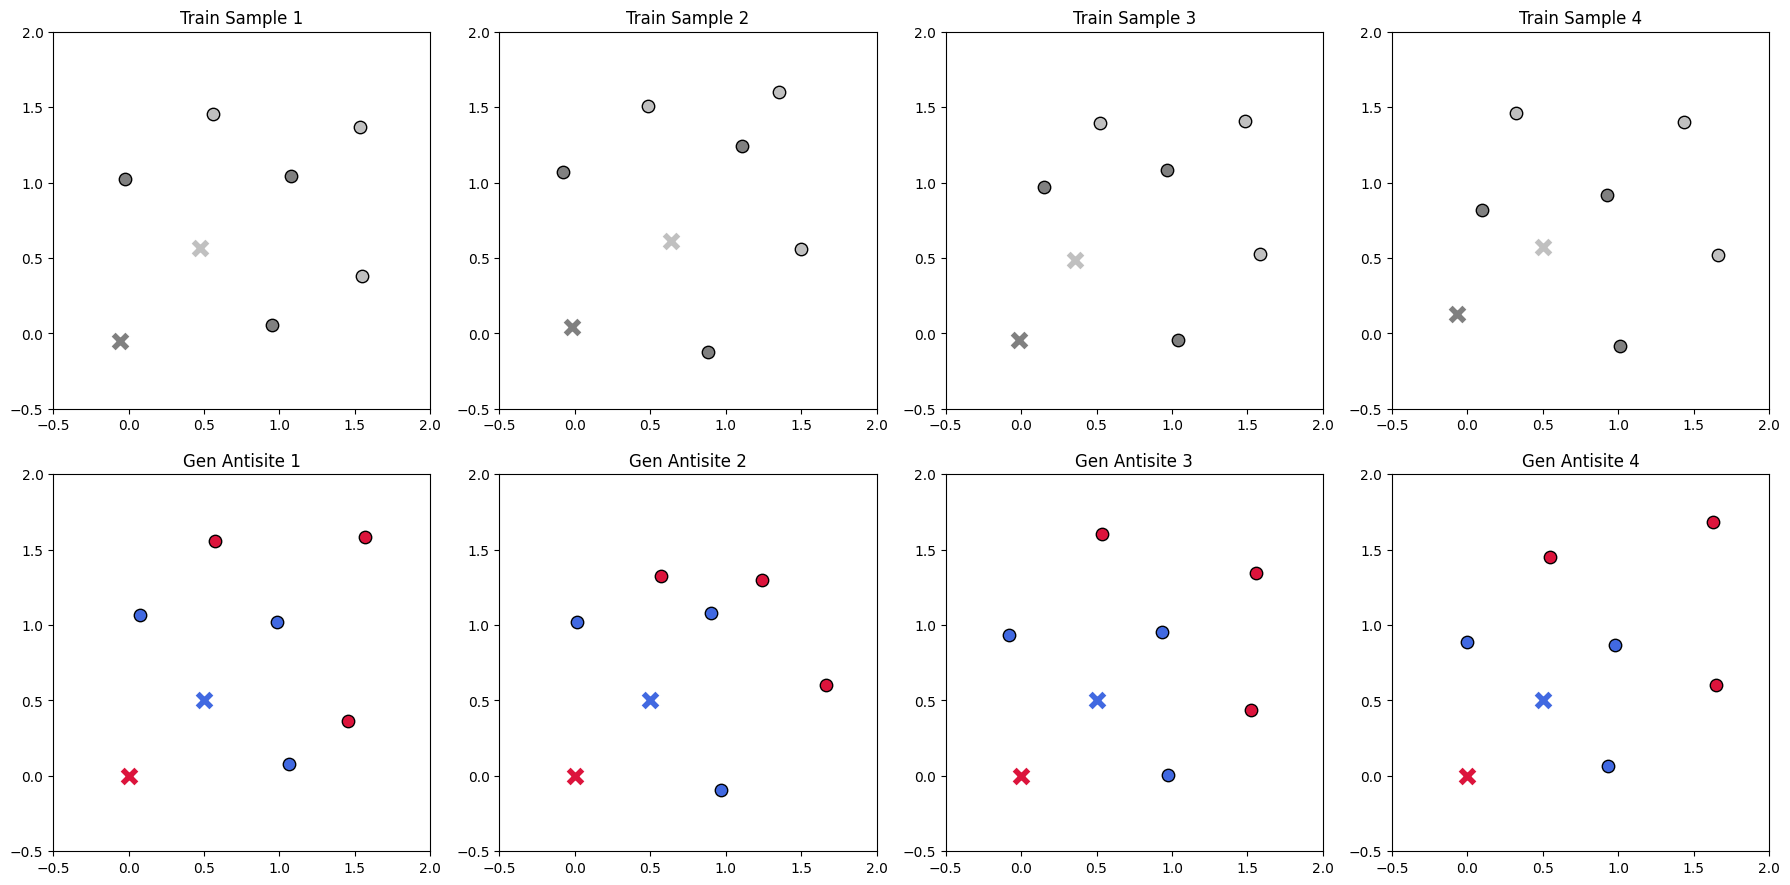

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# --- 1. GPU SETUP ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# --- 2. DATA GENERATION ---
def get_antisite_mini_data(n_samples=5000, grid_size=2):
    x = np.arange(grid_size)
    y = np.arange(grid_size)
    xv, yv = np.meshgrid(x, y)
    pos_A = np.stack([xv.flatten(), yv.flatten()], axis=1)
    pos_B = np.stack([xv.flatten() + 0.5, yv.flatten() + 0.5], axis=1)
    n_per_type = grid_size**2
    total_atoms = n_per_type * 2

    data = []
    labels = []
    for _ in range(n_samples):
        current_A, current_B = pos_A.copy(), pos_B.copy()
        has_defect = False
        if np.random.rand() > 0.5:
            current_A[0], current_B[0] = current_B[0].copy(), current_A[0].copy()
            has_defect = True
        full_pos = np.concatenate([current_A, current_B], axis=0)
        jitter = np.random.normal(0, 0.08, full_pos.shape)
        data.append(full_pos + jitter)
        labels.append(has_defect)
    return torch.tensor(np.array(data), dtype=torch.float32).to(device), total_atoms, n_per_type, labels

# --- 3. MLP MODEL ---
class LatticeScoreNet(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim + 1, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, input_dim)
        )
    def forward(self, x, t):
        t_tensor = torch.full((x.shape[0], 1), t, device=x.device)
        xt = torch.cat([x, t_tensor], dim=1)
        return self.net(xt)

# --- 4. TRAIN (FIXED PRINTING) ---
grid_size = 2
train_data, n_atoms, n_per_type, train_labels = get_antisite_mini_data()
input_dim = n_atoms * 2
n_steps = 200
betas = torch.linspace(1e-4, 0.02, n_steps).to(device)
model = LatticeScoreNet(input_dim).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=8e-4)

print("Training 'antisite-mini'...")
for epoch in range(1501):
    optimizer.zero_grad()
    t_idx = np.random.randint(1, n_steps)
    alpha_bar = torch.prod(1 - betas[:t_idx])
    noise = torch.randn_like(train_data).to(device)
    x_t = torch.sqrt(alpha_bar) * train_data + torch.sqrt(1 - alpha_bar) * noise

    # Flattening for the MLP
    pred_noise = model(x_t.view(-1, input_dim), t_idx/n_steps)
    loss = nn.MSELoss()(pred_noise, noise.view(-1, input_dim))

    loss.backward()
    optimizer.step()

    # Restored print statement!
    if epoch % 300 == 0:
        print(f"Epoch {epoch:04d} | Loss: {loss.item():.5f}")

# --- 5. SAMPLING ---
@torch.no_grad()
def sample_gen(n_batch=4):
    model.eval()
    x = torch.randn((n_batch, input_dim)).to(device)
    for t in reversed(range(1, n_steps)):
        z = torch.randn_like(x) if t > 1 else 0
        alpha, alpha_bar = 1 - betas[t], torch.prod(1 - betas[:t])
        noise_pred = model(x, t/n_steps)
        x = (1 / torch.sqrt(alpha)) * (x - ((1 - alpha) / torch.sqrt(1 - alpha_bar)) * noise_pred)
        x = x + torch.sqrt(betas[t]) * z
        # Pinning Antisite at Site 0 for Type A and Type B
        x[:, 0:2] = torch.tensor([0.5, 0.5], device=device) # A moves to B site
        x[:, n_per_type*2 : n_per_type*2+2] = torch.tensor([0.0, 0.0], device=device) # B moves to A site
    return x.view(n_batch, n_atoms, 2).cpu().numpy()

# --- 6. PLOTTING ---
train_samples = train_data[:4].cpu().numpy()
gen_samples = sample_gen(n_batch=4)

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for i in range(4):
    # Training Data Plotting
    sample_tr = train_samples[i]
    tA_tr, tB_tr = sample_tr[:n_per_type], sample_tr[n_per_type:]
    axes[0, i].scatter(tA_tr[1:,0], tA_tr[1:,1], c='gray', edgecolors='k', s=80)
    axes[0, i].scatter(tB_tr[1:,0], tB_tr[1:,1], c='silver', edgecolors='k', s=80)
    axes[0, i].scatter(tA_tr[0,0], tA_tr[0,1], c='gray', marker='X', s=200, edgecolors='white')
    axes[0, i].scatter(tB_tr[0,0], tB_tr[0,1], c='silver', marker='X', s=200, edgecolors='white')
    axes[0, i].set_title(f"Train Sample {i+1}")

    # Generated Data Plotting
    sample_gen_data = gen_samples[i]
    tA_g, tB_g = sample_gen_data[:n_per_type], sample_gen_data[n_per_type:]
    axes[1, i].scatter(tA_g[1:,0], tA_g[1:,1], c='royalblue', edgecolors='k', s=80)
    axes[1, i].scatter(tB_g[1:,0], tB_g[1:,1], c='crimson', edgecolors='k', s=80)
    axes[1, i].scatter(tA_g[0,0], tA_g[0,1], c='royalblue', marker='X', s=200, edgecolors='white')
    axes[1, i].scatter(tB_g[0,0], tB_g[0,1], c='crimson', marker='X', s=200, edgecolors='white')
    axes[1, i].set_title(f"Gen Antisite {i+1}")

    for row in range(2):
        axes[row, i].set_xlim(-0.5, 2.0); axes[row, i].set_ylim(-0.5, 2.0); axes[row, i].set_aspect('equal')

plt.tight_layout()
plt.show()